# 서부정류장역·만촌역 일별 승하차 예측

압축을 풀고 Python 3.12 커널에서 **모두 실행**하세요. 두 입력 CSV로 학습·평가·예측을 실행하고 결과 CSV 두 개를 저장합니다.

| 구분 | 기간 |
|---|---|
| 입력 실적 | 2021-01-01~2026-08-31 |
| 과거 시험 | 2024-09-01~2026-08-31 |
| 다음 365일 예측 | 2026-09-01~2027-08-31 |

승차와 하차는 이용 건수이며, 고유 이용자 수가 아닙니다.

## 1. 입력 확인

노트북과 같은 폴더의 `data/일별승하차.csv`, `data/공휴일.csv`를 읽습니다.
공휴일의 발표일은 예측 시점에 알 수 있었던 일정만 사용하는 데 필요합니다.

In [1]:
from pathlib import Path
from time import perf_counter
실행시작 = perf_counter()

프로젝트폴더 = Path.cwd()
필수파일 = ['data/일별승하차.csv', 'data/공휴일.csv']
if not all((프로젝트폴더 / p).is_file() for p in 필수파일):
    # 일부 실행기는 노트북의 상위 폴더를 작업 폴더로 사용합니다.
    후보폴더 = [p for p in 프로젝트폴더.iterdir()
                if p.is_dir() and (p / '서부정류장_만촌역_수요예측.ipynb').is_file()
                and all((p / f).is_file() for f in 필수파일)]
    if len(후보폴더) != 1:
        raise FileNotFoundError('압축을 모두 푼 폴더에서 노트북을 열어 주세요. data 폴더의 CSV 두 개가 필요합니다.')
    프로젝트폴더 = 후보폴더[0]

import hashlib
import warnings
from datetime import timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, dates as mdates
from IPython.display import display
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore', message="The 'generic' unit for NumPy timedelta.*", category=DeprecationWarning)
get_ipython().run_line_magic('matplotlib', 'inline')
font_names = {f.name for f in font_manager.fontManager.ttflist}
한국어글꼴 = next((f for f in ['Malgun Gothic','AppleGothic','NanumGothic','Noto Sans CJK KR'] if f in font_names), None)
if 한국어글꼴:
    plt.rcParams['font.family'] = 한국어글꼴
else:
    print('한국어 글꼴을 찾지 못했습니다. 나눔고딕 또는 맑은 고딕을 설치하면 그래프 글자가 표시됩니다.')
plt.rcParams.update({'axes.unicode_minus':False, 'font.size':10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 80)
pd.set_option('display.max_colwidth', 100)

TARGETS = ['board','alight']
SEED, HORIZON, CONTEXT = 20261019, 365, 730
ORIGINS = {'validation':['2022-12-31','2023-08-31'], 'test':['2024-08-31','2025-08-31']}
MODEL_LABELS = {'weekday_median8':'최근 8주 요일 중앙값', 'seasonal_364':'최근 52주 반복'}

STATIONS = {'서부정류장':1230, '만촌':2350}
INPUT_COLUMNS = {'역명':'station','역번호':'station_code','날짜':'date','승차(건)':'board','하차(건)':'alight'}
HOLIDAY_COLUMNS = {'날짜':'date','공휴일명':'name','발표일':'known_at'}

def read_actuals():
    a = pd.read_csv(프로젝트폴더/'data/일별승하차.csv').rename(columns=INPUT_COLUMNS)
    required = {'station','station_code','date',*TARGETS}
    if required - set(a.columns):
        raise ValueError('일별 실적에 역명, 역번호, 날짜, 승차(건), 하차(건)이 필요합니다.')
    a['date'] = pd.to_datetime(a.date, errors='raise')
    if set(a.station) != set(STATIONS) or a.duplicated(['station','date']).any():
        raise ValueError('두 역의 이름 또는 역별 날짜 중복을 확인하세요.')
    result = {}
    for station, station_code in STATIONS.items():
        g = a.loc[a.station.eq(station)].copy()
        if not g.station_code.eq(station_code).all():
            raise ValueError(f'{station}: 역번호가 일치하지 않습니다.')
        g = g.set_index('date')[TARGETS].sort_index().apply(pd.to_numeric,errors='raise')
        expected = pd.date_range(g.index.min(),g.index.max(),freq='D',name='date')
        if g.empty or not g.index.equals(expected):
            raise ValueError(f'{station}: 날짜 누락 또는 중복이 있습니다.')
        if not np.isfinite(g.to_numpy()).all() or (g<0).any().any() or not np.equal(g,np.floor(g)).all().all():
            raise ValueError(f'{station}: 수치 결측·음수·비정수 값을 확인하세요.')
        if g.index.min()>pd.Timestamp('2021-01-01') or g.index.max()<pd.Timestamp('2026-08-31'):
            raise ValueError(f'{station}: 보존된 과거 평가 기간의 실적이 필요합니다.')
        result[station] = g.astype(float)
    if len({g.index.max() for g in result.values()}) != 1:
        raise ValueError('두 역의 마지막 실적일이 같아야 같은 기간을 예측할 수 있습니다.')
    return result

역별실적 = read_actuals()
공휴일원장 = pd.read_csv(프로젝트폴더/'data/공휴일.csv',keep_default_na=False).rename(columns=HOLIDAY_COLUMNS)
for col in ['date','known_at']:
    공휴일원장[col] = pd.to_datetime(공휴일원장[col],errors='raise')
if 공휴일원장[['date','known_at']].isna().any().any() or 공휴일원장.date.duplicated().any():
    raise ValueError('공휴일 날짜·발표일 결측 또는 날짜 중복이 있습니다.')
if 공휴일원장.name.eq('').any():
    raise ValueError('공휴일명이 비어 있습니다.')
display(pd.DataFrame([{'역명':s,'역번호':STATIONS[s],'시작일':g.index.min().strftime('%Y-%m-%d'),
    '종료일':g.index.max().strftime('%Y-%m-%d'),'일수':len(g),
    '검사결과':'날짜 누락·중복, 수치 결측·음수·비정수 없음'} for s,g in 역별실적.items()]))
display(pd.DataFrame([{'자료':'공휴일 원장','행수':len(공휴일원장),
    '시작일':공휴일원장.date.min().strftime('%Y-%m-%d'),'종료일':공휴일원장.date.max().strftime('%Y-%m-%d')}]))

,역명,역번호,시작일,종료일,일수,검사결과
0,서부정류장,1230,2021-01-01,2026-08-31,2069,"날짜 누락·중복, 수치 결측·음수·비정수 없음"
1,만촌,2350,2021-01-01,2026-08-31,2069,"날짜 누락·중복, 수치 결측·음수·비정수 없음"


,자료,행수,시작일,종료일
0,공휴일 원장,139,2021-01-01,2027-12-27


## 2. 달력 특징

요일·계절·공휴일·명절 전후·연휴 길이를 사용합니다.
각 예측 기준일까지 발표된 공휴일만 반영하며, 예측 기간의 실제 승하차는 입력하지 않습니다.

In [2]:
CONTEXT_COLUMNS = [
    'ctx_named_holiday', 'ctx_workers_day', 'ctx_nonworking',
    'ctx_bridge_workday', 'ctx_nonwork_run_length',
    'ctx_nonwork_run_position', 'ctx_nonwork_run_remaining',
    'ctx_previous_nonwork_run', 'ctx_next_nonwork_run',
    'ctx_days_since_named_holiday', 'ctx_days_until_named_holiday',
    'ctx_named_holiday_prev7', 'ctx_named_holiday_next7',
    'ctx_lunar_period', 'ctx_lunar_core', 'ctx_lunar_family',
    'ctx_lunar_distance', 'ctx_lunar_near7',
]

def _holidays(frame):
    if {'date', 'name', 'known_at'} - set(frame.columns):
        raise ValueError('공휴일 자료에는 date, name, known_at 열이 필요합니다.')
    h = frame.copy()
    for col in ['date', 'known_at']:
        h[col] = pd.to_datetime(h[col], errors='raise').dt.normalize()
        if h[col].isna().any():
            raise ValueError(f'공휴일 {col}에 결측값이 있습니다.')
    if h['date'].duplicated().any():
        raise ValueError('공휴일 원장 날짜가 중복됩니다.')
    return h.sort_values('date').reset_index(drop=True)

def _shift(day, days):
    return day + timedelta(days=days)

def _continuous_run(day, named):
    """Saturday/Sunday plus announced named holidays; not every worker's leave."""
    def off(d):
        return d.dayofweek >= 5 or d in named
    if not off(day):
        return None
    start = end = day
    while off(_shift(start, -1)):
        start = _shift(start, -1)
    while off(_shift(end, 1)):
        end = _shift(end, 1)
    return start, end

def calendar_context(index, holidays=None, issue_date=None):
    """예측 기준일까지 알려진 달력으로 특징을 만듭니다."""
    idx = pd.DatetimeIndex(index)
    if idx.tz is not None or not (idx == idx.normalize()).all():
        raise ValueError('목표 날짜는 시간대 없는 자정 날짜로 입력하세요.')
    h = _holidays(공휴일원장 if holidays is None else holidays)
    fixed = pd.Timestamp(issue_date).normalize() if issue_date is not None else None
    if fixed is not None and fixed.tzinfo is not None:
        raise ValueError('발행일은 시간대 없는 날짜로 입력하세요.')
    rows = []
    for day in idx:
        issued = fixed if fixed is not None else _shift(day, -1)
        known = h.loc[h['known_at'].le(issued)]
        named = set(known['date'])
        row = dict.fromkeys(CONTEXT_COLUMNS, 0)
        row['ctx_named_holiday'] = int(day in named)
        row['ctx_workers_day'] = int(day.month == 5 and day.day == 1)
        run = _continuous_run(day, named)
        row['ctx_nonworking'] = int(run is not None)
        if run is not None:
            start, end = run
            row['ctx_nonwork_run_length'] = (end - start).days + 1
            row['ctx_nonwork_run_position'] = (day - start).days + 1
            row['ctx_nonwork_run_remaining'] = (end - day).days
        else:
            prev = _continuous_run(_shift(day, -1), named)
            nex = _continuous_run(_shift(day, 1), named)
            row['ctx_bridge_workday'] = int(prev is not None and nex is not None)
            row['ctx_previous_nonwork_run'] = (prev[1] - prev[0]).days + 1 if prev else 0
            row['ctx_next_nonwork_run'] = (nex[1] - nex[0]).days + 1 if nex else 0
        previous = [n for n in range(1, 8) if _shift(day, -n) in named]
        following = [n for n in range(1, 8) if _shift(day, n) in named]
        row['ctx_named_holiday_prev7'] = len(previous)
        row['ctx_named_holiday_next7'] = len(following)
        row['ctx_days_since_named_holiday'] = min(previous, default=8)
        row['ctx_days_until_named_holiday'] = min(following, default=8)
        row['ctx_lunar_distance'] = 99
        centers = known.loc[known['name'].isin(['설날', '추석'])]
        for center in centers.itertuples(index=False):
            offset = (day - center.date).days
            # An unusually long officially announced run can extend beyond
            # the +/-7 model proximity window; it remains a lunar day type.
            core = [_shift(center.date, k) for k in [-1, 0, 1]]
            for core_day in core:
                if core_day not in named:
                    continue
                lunar_run = _continuous_run(core_day, named)
                if lunar_run and lunar_run[0] <= day <= lunar_run[1]:
                    row['ctx_lunar_period'] = 1
            if abs(offset) <= 7:
                row['ctx_lunar_near7'] = 1
                row['ctx_lunar_distance'] = offset
                row['ctx_lunar_family'] = 1 if center.name == '설날' else 2
                row['ctx_lunar_core'] = int(abs(offset) <= 1)
                # The target core date must itself be announced, rather than
                # inferred a public holiday from the mere name of the main day.
                row['ctx_lunar_core'] *= int(day in named)
        rows.append(row)
    return pd.DataFrame(rows, index=idx, columns=CONTEXT_COLUMNS).astype(float)

In [3]:
def holidays():
    return 공휴일원장.copy()

def calendar(index, issue_date):
    idx = pd.DatetimeIndex(index)
    h = holidays()
    f = calendar_context(idx, holidays=h, issue_date=issue_date)
    f['dow_sin'] = np.sin(2*np.pi*idx.dayofweek/7)
    f['dow_cos'] = np.cos(2*np.pi*idx.dayofweek/7)
    for k in [1, 2, 3]:
        f[f'year_sin{k}'] = np.sin(2*np.pi*k*(idx.dayofyear-1)/365.25)
        f[f'year_cos{k}'] = np.cos(2*np.pi*k*(idx.dayofyear-1)/365.25)
    for day in range(7):
        f[f'dow_{day}'] = (idx.dayofweek == day).astype(float)
    f['month'] = idx.month.astype(float)
    f['trend_years'] = (idx-pd.Timestamp('2021-01-01')).days.to_numpy()/365.25
    return f.astype(float)

def history_and_dates(actuals, origin, days=HORIZON):
    origin = pd.Timestamp(origin).normalize()
    if days != HORIZON:
        raise ValueError('이 버전은 연속 365일 예측으로 검증되었습니다.')
    history = actuals.loc[:origin].tail(CONTEXT).copy()
    if len(history) != CONTEXT or history.index.max() != origin:
        raise ValueError('기준일까지 연속된 730일 실적이 필요합니다.')
    dates = pd.date_range(origin+pd.Timedelta(days=1), periods=days, name='date')
    if dates.max() > pd.Timestamp('2027-12-31'):
        raise ValueError('공휴일 원장은 2027년까지 확인했습니다. 이후 달력을 먼저 갱신하세요.')
    return history, dates

def baseline(history, dates, method):
    origin = history.index.max()
    if method == 'weekday_median8':
        profiles = history.tail(56).groupby(history.tail(56).index.dayofweek).median()
        return profiles.loc[dates.dayofweek, TARGETS].to_numpy()
    # Repeat the last observed 52 weeks. Day 365 also references an observed
    # date, never the newly forecast day 1 or its unavailable actual value.
    refs = pd.DatetimeIndex([d-pd.Timedelta(days=364*int(np.ceil((d-origin).days/364))) for d in dates])
    assert refs.max() <= origin
    return history.loc[refs, TARGETS].to_numpy()

def metric(truth, prediction):
    t, p = np.asarray(truth, float), np.asarray(prediction, float)
    error = p-t
    return {'n': len(t), 'mae': float(np.abs(error).mean()),
            'rmse': float(np.sqrt(np.mean(error**2))),
            'wape_pct': float(np.abs(error).sum()/t.sum()*100),
            'bias': float(error.mean()),
            'sum_error_pct': float(error.sum()/t.sum()*100)}

## 3. 적용 모델

| 역 | 모델 | 최종 학습 |
|---|---|---|
| 서부정류장 | CatBoost, RMSE 손실 | 최근 1,095일 |
| 만촌 | CatBoost와 추세 회귀를 50:50 평균 | 최근 1,095일 |

설정은 기존 검증에서 선정한 값을 고정합니다. 아래에서는 이 설정과 기존 730일 CatBoost·두 기준선을 다시 학습해 비교합니다.
추세 회귀는 최근 자료에 더 큰 가중치를 주고, 미래 추세의 배율을 1/1.15~1.15로 제한합니다.

In [4]:
모델설정 = [{'id': 'CatBoost_MAE_730_h0_separate', 'family': 'CatBoost', 'loss': 'MAE', 'window': '730', 'half_life': 0, 'target': 'separate'}, {'id': 'CatBoost_RMSE_1095_h0_separate', 'family': 'CatBoost', 'loss': 'RMSE', 'window': '1095', 'half_life': 0, 'target': 'separate'}, {'id': 'CatBoost_MAE_1095_h0_separate', 'family': 'CatBoost', 'loss': 'MAE', 'window': '1095', 'half_life': 0, 'target': 'separate'}, {'id': 'RidgeTrend_1095', 'family': 'RidgeTrend', 'window': '1095', 'half_life': 365, 'target': 'separate'}, {'id': 'Blend_1095', 'family': 'Blend', 'window': '1095', 'members': ['CatBoost_MAE_1095_h0_separate', 'RidgeTrend_1095']}, {'id': 'weekday_median8', 'family': 'Baseline', 'window': '730'}, {'id': 'seasonal_364', 'family': 'Baseline', 'window': '730'}]
SPEC_BY_ID = {s['id']:s for s in 모델설정}
MODEL_LABELS.update({'CatBoost_MAE_730_h0_separate': 'CatBoost · MAE · 최근 730일 · 동일가중 · 승하차별', 'CatBoost_RMSE_1095_h0_separate': 'CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별', 'CatBoost_MAE_1095_h0_separate': 'CatBoost · MAE · 최근 1,095일 · 동일가중 · 승하차별', 'RidgeTrend_1095': '완만한 추세 회귀 · 최근 1,095일', 'Blend_1095': 'CatBoost·추세 회귀 50:50 · 최근 1,095일'})

_OPT_FEATURE_CACHE = {}
_OPT_PREDICTION_CACHE = {}

def optimized_history(actuals, origin, window):
    origin = pd.Timestamp(origin)
    hist = actuals.loc[:origin, TARGETS].copy()
    if window in ("730", "1095"):
        hist = hist.tail(int(window))
    elif window == "since2022":
        hist = hist.loc["2022-01-01":]
    elif window != "all2021":
        raise ValueError("알 수 없는 학습기간")
    if len(hist) < 365 or hist.index.max() != origin:
        raise ValueError("기준일까지 365일 이상 연속된 자료가 필요합니다.")
    assert hist.index.equals(pd.date_range(hist.index.min(), origin, name=hist.index.name))
    return hist

def optimized_features(index, origin):
    index = pd.DatetimeIndex(index)
    key = (str(index.min()), str(index.max()), str(pd.Timestamp(origin)))
    if key not in _OPT_FEATURE_CACHE:
        _OPT_FEATURE_CACHE[key] = calendar(index, pd.Timestamp(origin))
    return _OPT_FEATURE_CACHE[key].copy()

def predict_candidate(candidate_id, actuals, origin):
    """Only inputs <= origin; fixed 365-day future, no actual future lags."""
    spec = SPEC_BY_ID[candidate_id]
    origin = pd.Timestamp(origin)
    # The digest prevents reusing another station's predictions or edited inputs.
    hist = optimized_history(actuals, origin, spec["window"])
    digest = hashlib.sha256(pd.util.hash_pandas_object(hist, index=True).values.tobytes()).hexdigest()
    key = (candidate_id, str(origin), digest)
    if key in _OPT_PREDICTION_CACHE:
        return _OPT_PREDICTION_CACHE[key].copy()
    dates = pd.date_range(origin+pd.Timedelta(days=1), periods=HORIZON, name="date")
    if dates.max() > pd.Timestamp("2027-12-31"):
        raise ValueError("2027년 이후 공휴일 원장을 보완하세요.")
    if spec["family"] == "Blend":
        out = np.mean([predict_candidate(member, actuals, origin) for member in spec["members"]], axis=0)
    elif spec["family"] == "Baseline":
        baseline_history, baseline_dates = history_and_dates(actuals, origin)
        out = baseline(baseline_history, baseline_dates, candidate_id)
    else:
        past = optimized_features(hist.index, origin)
        future = optimized_features(dates, origin)
        weights = np.ones(len(hist))
        if spec["half_life"]:
            weights = 2.0**(-np.asarray((origin-hist.index).days)/spec["half_life"])
        if spec["family"] == "RidgeTrend":
            # Linear trend + smooth seasonality. No inspection-based bias correction.
            # Trend relative to issue day is capped to +/-15% across one forecast year.
            cols = ["trend_years"] + [c for c in past if c.startswith("year_") or
                c.startswith("dow_") or c in ["ctx_named_holiday", "ctx_workers_day",
                "ctx_lunar_core", "ctx_lunar_period", "ctx_bridge_workday"]]
            x = past[cols].to_numpy()
            f = future[cols].to_numpy()
            center, scale = x.mean(axis=0), x.std(axis=0)
            scale[scale < 1e-8] = 1
            x = np.column_stack([np.ones(len(x)), (x-center)/scale])
            f = np.column_stack([np.ones(len(f)), (f-center)/scale])
            penalty = np.eye(x.shape[1])*20.0
            penalty[0, 0] = 1e-8
            y = np.log1p(hist[TARGETS].to_numpy())
            coef = np.linalg.solve(x.T@(weights[:,None]*x)+penalty,
                                   x.T@(weights[:,None]*y))
            raw_log = f@coef
            origin_trend = (past["trend_years"].iloc[-1]-center[0])/scale[0]
            change = (f[:,1]-origin_trend)[:,None]*coef[1,:]
            clipped = np.clip(change, -np.log(1.15), np.log(1.15))
            out = np.expm1(raw_log-change+clipped)
        else:
            y = hist[TARGETS].to_numpy()
            if spec["target"] == "total":
                y = y.sum(axis=1, keepdims=True)
            predicted = []
            for j in range(y.shape[1]):
                if spec["loss"] == "MAE":
                    params = dict(iterations=450, learning_rate=.035, depth=5, l2_leaf_reg=8)
                else:
                    params = dict(iterations=550, learning_rate=.035, depth=4, l2_leaf_reg=12)
                model = CatBoostRegressor(**params, loss_function=spec["loss"],
                    random_seed=SEED, verbose=False, thread_count=4, allow_writing_files=False)
                model.fit(past.to_numpy(dtype=np.float32), y[:,j].astype(np.float32),
                          sample_weight=weights)
                predicted.append(model.predict(future.to_numpy(dtype=np.float32)))
            out = np.column_stack(predicted)
            if spec["target"] == "total":
                recent = hist.tail(364)
                by_dow = recent.groupby(recent.index.dayofweek).sum()
                share = (by_dow["board"]/by_dow.sum(axis=1)).fillna(.5)
                proportions = share.loc[dates.dayofweek].to_numpy()
                out = np.column_stack([out[:,0]*proportions, out[:,0]*(1-proportions)])
    out = np.maximum(0, np.asarray(out, dtype=float))
    assert out.shape == (365, 2) and np.isfinite(out).all()
    _OPT_PREDICTION_CACHE[key] = out.copy()
    return out

## 4. 과거 평가

검증 기준일은 2022-12-31·2023-08-31, 시험 기준일은 2024-08-31·2025-08-31입니다.
각 기준일 다음 365일을 한 번에 예측하며, 중간에 실제값으로 갱신하지 않습니다.
검증기간 일부는 겹칩니다. 시험기간은 이전 비교에도 사용한 과거 구간입니다.

In [5]:
역별모델 = {'만촌': 'Blend_1095', '서부정류장': 'CatBoost_RMSE_1095_h0_separate'}
기존설정 = 'CatBoost_MAE_730_h0_separate'
성적열이름 = {'station': '역명', 'model': '모델', 'candidate': '모델', 'origin': '실적기준일', 'n': '평가일수', 'mae': '평균절대오차(건)', 'rmse': '제곱평균제곱근오차(건)', 'wape_pct': '전체대비절대오차율(%)', 'bias': '평균예측편차(건)', 'sum_error_pct': '합계예측오차율(%)'}

def show_scores(frame):
    f=frame.copy()
    for col in ['model','candidate']:
        if col in f:
            f[col]=f[col].replace(MODEL_LABELS)
    display(f.rename(columns=성적열이름).round(3))

def evaluate_candidates(stage, station_models):
    frames=[]
    for station,actuals in 역별실적.items():
        for origin_text in ORIGINS[stage]:
            origin=pd.Timestamp(origin_text)
            dates=pd.date_range(origin+pd.Timedelta(days=1),periods=HORIZON)
            assert dates.max()<=actuals.index.max()
            for name in station_models[station]:
                values=predict_candidate(name,actuals.loc[:origin].copy(),origin)
                f=pd.DataFrame({'station':station,'station_code':STATIONS[station],
                    'date':dates,'origin':origin,'model':name,'lead':np.arange(1,HORIZON+1)})
                for j,target in enumerate(TARGETS):
                    f['actual_'+target]=actuals.loc[dates,target].to_numpy()
                    f['pred_'+target]=values[:,j]
                f['actual_total']=f.actual_board+f.actual_alight
                f['pred_total']=f.pred_board+f.pred_alight
                f['actual_named_holiday']=dates.isin(공휴일원장.date).astype(int)
                frames.append(f)
    return pd.concat(frames,ignore_index=True)

비교모델 = {s:list(dict.fromkeys([역별모델[s],기존설정,'weekday_median8','seasonal_364'])) for s in STATIONS}
재계산검증 = evaluate_candidates('validation', {s:list(dict.fromkeys([역별모델[s],기존설정])) for s in STATIONS})
검증회차성적 = pd.DataFrame([{'station':s,'candidate':c,'origin':o,**metric(g.actual_total,g.pred_total)}
    for (s,c,o),g in 재계산검증.groupby(['station','model','origin'])])
재계산성적 = 검증회차성적.groupby(['station','candidate'],as_index=False)[['mae','wape_pct','bias']].mean()
print('적용 모델과 기존 설정의 검증 성적: 두 기준일의 평균')
show_scores(재계산성적)
시험예측 = evaluate_candidates('test',비교모델)
시험성적 = pd.DataFrame([{'station':s,'model':m,**metric(g.actual_total,g.pred_total)}
    for (s,m),g in 시험예측.groupby(['station','model'])])
print('시험 성적: 적용 모델·기존 설정·기준선')
show_scores(시험성적)

적용 모델과 기존 설정의 검증 성적: 두 기준일의 평균


,역명,모델,평균절대오차(건),전체대비절대오차율(%),평균예측편차(건)
0,만촌,"CatBoost·추세 회귀 50:50 · 최근 1,095일",354.516,4.965,-4.004
1,만촌,CatBoost · MAE · 최근 730일 · 동일가중 · 승하차별,420.750,5.897,-259.390
2,서부정류장,CatBoost · MAE · 최근 730일 · 동일가중 · 승하차별,791.810,5.237,100.287
3,서부정류장,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",766.380,5.069,-49.725


시험 성적: 적용 모델·기존 설정·기준선


,역명,모델,평가일수,평균절대오차(건),제곱평균제곱근오차(건),전체대비절대오차율(%),평균예측편차(건),합계예측오차율(%)
0,만촌,"CatBoost·추세 회귀 50:50 · 최근 1,095일",730,603.689,790.901,7.349,-463.664,-5.645
1,만촌,CatBoost · MAE · 최근 730일 · 동일가중 · 승하차별,730,707.824,893.785,8.617,-581.074,-7.074
2,만촌,최근 52주 반복,730,1121.919,1671.381,13.658,-731.034,-8.900
3,만촌,최근 8주 요일 중앙값,730,1204.699,1510.488,14.666,-832.568,-10.136
4,서부정류장,CatBoost · MAE · 최근 730일 · 동일가중 · 승하차별,730,678.374,951.953,4.421,-23.520,-0.153
5,서부정류장,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",730,663.706,918.775,4.325,-80.240,-0.523
6,서부정류장,최근 52주 반복,730,1180.268,1896.631,7.691,-154.989,-1.010
7,서부정류장,최근 8주 요일 중앙값,730,1193.770,1592.863,7.779,-524.334,-3.417


## 5. 예측 오차

MAE는 하루 절대오차의 평균, WAPE는 전체 실제값 대비 절대오차율, MAPE는 날짜별 절대비율오차의 평균입니다.
평균예측편차가 음수이면 과소예측입니다.
14일 블록 비교의 구간에 0이 포함되면 기존 설정보다 확실히 좋아졌다고 단정하기 어렵습니다.

,역명,구분,평가일수,평균절대오차(건),제곱평균제곱근오차(건),전체대비절대오차율(%),평균예측편차(건),합계예측오차율(%)
0,서부정류장,전체,730,663.706,918.775,4.325,-80.240,-0.523
1,서부정류장,공휴일,41,1382.935,1712.049,11.416,472.712,3.902
2,서부정류장,공휴일 외,689,620.907,848.505,3.996,-113.144,-0.728
3,서부정류장,기준일 이후 1~50일,100,743.576,1053.029,4.876,-22.048,-0.145
4,서부정류장,기준일 이후 51~100일,100,416.366,555.091,2.623,-182.345,-1.149
5,서부정류장,기준일 이후 101~180일,160,749.306,1020.433,5.002,-96.970,-0.647
6,서부정류장,기준일 이후 181~365일,370,671.952,912.264,4.367,-61.137,-0.397
7,만촌,전체,730,603.689,790.901,7.349,-463.664,-5.645
8,만촌,공휴일,41,917.563,1318.976,19.455,421.907,8.946
9,만촌,공휴일 외,689,585.012,747.813,6.946,-516.362,-6.131


,역명,평가대상,평가일수,평균절대오차(건),제곱평균제곱근오차(건),전체대비절대오차율(%),평균예측편차(건),합계예측오차율(%),평균절대비율오차(%),실제값0제외일수
0,서부정류장,승차,730,349.208,501.556,4.427,-35.883,-0.455,4.658,0
1,서부정류장,하차,730,324.905,445.882,4.357,-44.357,-0.595,4.632,0
2,서부정류장,승하차 합계,730,663.706,918.775,4.325,-80.240,-0.523,4.586,0
3,만촌,승차,730,328.948,449.330,7.905,-259.171,-6.228,7.949,0
4,만촌,하차,730,279.451,370.518,6.895,-204.493,-5.046,7.224,0
5,만촌,승하차 합계,730,603.689,790.901,7.349,-463.664,-5.645,7.559,0


,역명,월합계WAPE(%)
0,서부정류장,1.726
1,만촌,6.030


월합계 오차는 일별 과대·과소 예측이 상쇄될 수 있어 일별 오차와 구분합니다.


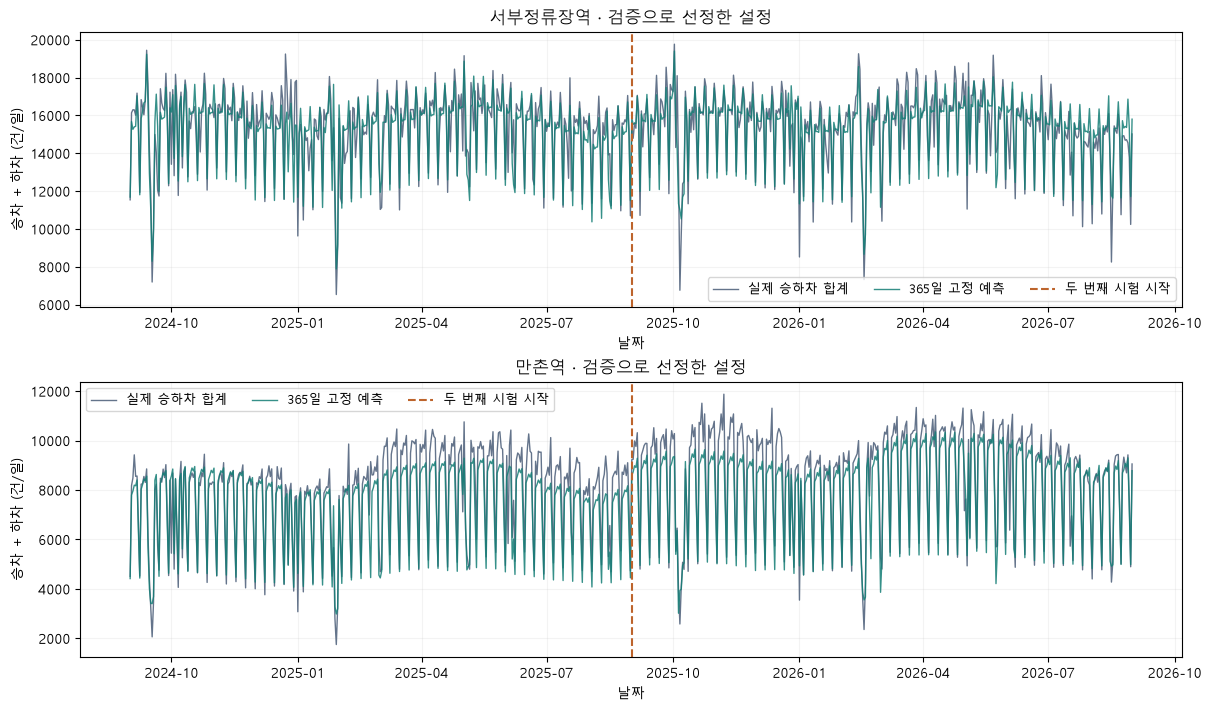

양수 감소율은 개선, 음수 감소율은 악화입니다. 시험 결과로 설정을 다시 선택하지 않습니다.


,역명,기존 MAE(건),선정 MAE(건),MAE 감소율(%),기존 WAPE(%),선정 WAPE(%),선정 평균편차(건),선정 총량편차(%)
0,서부정류장,678.374,663.706,2.162,4.421,4.325,-80.240,-0.523
1,만촌,707.824,603.689,14.712,8.617,7.349,-463.664,-5.645


기존 설정과의 MAE 차이: 14일 블록 재표집 95% 구간


,역명,MAE 차이(선정−기존),14일 블록 95% 하한,14일 블록 95% 상한,해석
0,서부정류장,-14.669,-41.058,8.704,0 포함: 향상 단정 어려움
1,만촌,-104.134,-134.862,-73.614,해당 과거자료에서 오차 감소


In [6]:
선택시험 = pd.concat([시험예측.loc[시험예측.station.eq(s)&시험예측.model.eq(m)]
    for s,m in 역별모델.items()],ignore_index=True).sort_values(['station_code','date']).reset_index(drop=True)
assert len(선택시험)==1460 and not 선택시험.duplicated(['station','date']).any()
부분성적, 대상성적 = [], []
for station,f in 선택시험.groupby('station',sort=False):
    for label,mask in [('전체',np.ones(len(f),dtype=bool)),('공휴일',f.actual_named_holiday.eq(1)),
        ('공휴일 외',f.actual_named_holiday.eq(0)),('기준일 이후 1~50일',f.lead.le(50)),
        ('기준일 이후 51~100일',f.lead.between(51,100)),('기준일 이후 101~180일',f.lead.between(101,180)),
        ('기준일 이후 181~365일',f.lead.ge(181))]:
        g=f.loc[mask]
        부분성적.append({'station':station,'구분':label,**metric(g.actual_total,g.pred_total)})
    for target,label in [('board','승차'),('alight','하차'),('total','승하차 합계')]:
        t,p=f['actual_'+target].to_numpy(),f['pred_'+target].to_numpy()
        valid=t!=0
        대상성적.append({'station':station,'평가대상':label,**metric(t,p),
            '평균절대비율오차(%)':float(np.mean(np.abs(p[valid]-t[valid])/np.abs(t[valid]))*100),
            '실제값0제외일수':int((~valid).sum())})
show_scores(pd.DataFrame(부분성적))
show_scores(pd.DataFrame(대상성적))
월오차행=[]
for station,f in 선택시험.groupby('station',sort=False):
    m=f.groupby(f.date.dt.to_period('M'))[['actual_total','pred_total']].sum()
    월오차행.append({'역명':station,'월합계WAPE(%)':metric(m.actual_total,m.pred_total)['wape_pct']})
display(pd.DataFrame(월오차행).round(3))
print('월합계 오차는 일별 과대·과소 예측이 상쇄될 수 있어 일별 오차와 구분합니다.')
fig,axes=plt.subplots(2,1,figsize=(12,7),constrained_layout=True)
for ax,(station,f) in zip(axes,선택시험.groupby('station',sort=False)):
    ax.plot(f.date,f.actual_total,label='실제 승하차 합계',color='#64748b',lw=1)
    ax.plot(f.date,f.pred_total,label='365일 고정 예측',color='#137d75',lw=1,alpha=.85)
    ax.axvline(pd.Timestamp('2025-09-01'),color='#bd642c',ls='--',label='두 번째 시험 시작')
    ax.set(title=f'{station}역 · 검증으로 선정한 설정',ylabel='승차 + 하차 (건/일)',xlabel='날짜')
    ax.legend(ncol=3,fontsize=9);ax.grid(alpha=.15)
plt.show()
개선비교=[]
for station in STATIONS:
    old=시험성적.loc[시험성적.station.eq(station)&시험성적.model.eq(기존설정)].iloc[0]
    new=시험성적.loc[시험성적.station.eq(station)&시험성적.model.eq(역별모델[station])].iloc[0]
    개선비교.append({'역명':station,'기존 MAE(건)':old.mae,'선정 MAE(건)':new.mae,
        'MAE 감소율(%)':(old.mae-new.mae)/old.mae*100,
        '기존 WAPE(%)':old.wape_pct,'선정 WAPE(%)':new.wape_pct,
        '선정 평균편차(건)':new.bias,'선정 총량편차(%)':new.sum_error_pct})
print('양수 감소율은 개선, 음수 감소율은 악화입니다. 시험 결과로 설정을 다시 선택하지 않습니다.')
display(pd.DataFrame(개선비교).round(3))
블록결과=[]
블록난수=np.random.default_rng(20261020)
for station in STATIONS:
    old=시험예측.loc[시험예측.station.eq(station)&시험예측.model.eq(기존설정)].sort_values('date')
    new=선택시험.loc[선택시험.station.eq(station)].sort_values('date')
    assert old.date.tolist()==new.date.tolist() and np.array_equal(old.actual_total,new.actual_total)
    delta=np.abs(new.pred_total.to_numpy()-new.actual_total.to_numpy())-np.abs(old.pred_total.to_numpy()-old.actual_total.to_numpy())
    draws=[]
    for _ in range(5000):
        sampled=[]
        for group in [delta[:365],delta[365:]]:
            starts=블록난수.integers(0,365,size=27)
            ids=(starts[:,None]+np.arange(14)[None,:])%365
            sampled.append(group[ids.ravel()[:365]])
        draws.append(np.concatenate(sampled).mean())
    lower,upper=np.quantile(draws,[.025,.975])
    블록결과.append({'역명':station,'MAE 차이(선정−기존)':delta.mean(),
        '14일 블록 95% 하한':lower,'14일 블록 95% 상한':upper,
        '해석':'0 포함: 향상 단정 어려움' if lower<=0<=upper else '해당 과거자료에서 오차 감소' if upper<0 else '해당 과거자료에서 오차 증가'})
print('기존 설정과의 MAE 차이: 14일 블록 재표집 95% 구간')
display(pd.DataFrame(블록결과).round(3))

## 6. 다음 365일 예측

2026-08-31까지의 최근 1,095일로 학습합니다.
아래 값은 역 전체의 일별 승하차 예측이며, 출입구별·연령별 이용량이나 시설 개선 효과를 나타내지 않습니다.

In [7]:
예측모음=[]
for station,actuals in 역별실적.items():
    origin=actuals.index.max()
    _,dates=history_and_dates(actuals,origin)
    훈련실적=optimized_history(actuals,origin,SPEC_BY_ID[역별모델[station]]['window'])
    raw_prediction=predict_candidate(역별모델[station],actuals,origin)
    counts=np.rint(raw_prediction).astype('int64')
    h=공휴일원장.loc[공휴일원장.known_at.le(origin)].set_index('date')['name']
    예측모음.append(pd.DataFrame({'역명':station,'역번호':STATIONS[station],
        '날짜':dates,'실적기준일':origin.strftime('%Y-%m-%d'),'기준일이후일수':np.arange(1,HORIZON+1),
        '모델':MODEL_LABELS[역별모델[station]],
        '학습시작일':훈련실적.index.min().strftime('%Y-%m-%d'),'학습종료일':origin.strftime('%Y-%m-%d'),'학습일수':len(훈련실적),'예측승차(건)':counts[:,0],'예측하차(건)':counts[:,1],
        '예측승하차합계(건)':counts.sum(axis=1),
        '요일':dates.dayofweek.map(dict(enumerate(['월','화','수','목','금','토','일']))),
        '공휴일명':dates.map(h).fillna(''),'공휴일여부':dates.isin(h.index).astype(int),
        '자료구분':'예측(실제값 미입력)','예측값여부':True}))
예측결과=pd.concat(예측모음,ignore_index=True)
월별예측=예측결과.assign(연월=예측결과['날짜'].dt.to_period('M').astype(str)).groupby(['역명','연월'],as_index=False).agg(
    일수=('날짜','size'),**{'예측승차(건)':('예측승차(건)','sum'),'예측하차(건)':('예측하차(건)','sum'),
    '예측승하차합계(건)':('예측승하차합계(건)','sum'),'하루평균승하차(건)':('예측승하차합계(건)','mean')})
연간예측=예측결과.groupby('역명',as_index=False).agg(
    시작일=('날짜','min'),종료일=('날짜','max'),일수=('날짜','size'),
    **{'예측승차(건)':('예측승차(건)','sum'),'예측하차(건)':('예측하차(건)','sum'),
       '예측승하차합계(건)':('예측승하차합계(건)','sum'),'하루평균승하차(건)':('예측승하차합계(건)','mean')})
print('두 역의 연간 예측 합계:')
display(연간예측.round(1))
print('월별 합계 — 두 역을 나란히 비교:')
display(월별예측.pivot(index='연월',columns='역명',values='예측승하차합계(건)').rename_axis(columns='역명'))
display(월별예측.round(1))
display(예측결과.groupby('역명',sort=False).head(7))

두 역의 연간 예측 합계:


,역명,시작일,종료일,일수,예측승차(건),예측하차(건),예측승하차합계(건),하루평균승하차(건)
0,만촌,2026-09-01,2027-08-31,365,1668791,1607848,3276639,8977.1
1,서부정류장,2026-09-01,2027-08-31,365,2743995,2595987,5339982,14630.1


월별 합계 — 두 역을 나란히 비교:


역명,만촌,서부정류장
연월,,
2026-09,255150,436175
2026-10,285099,462951
2026-11,279376,451491
2026-12,272311,456214
2027-01,257668,428993
2027-02,236112,399116
2027-03,299323,460046
2027-04,298078,463024
2027-05,285240,468388


,역명,연월,일수,예측승차(건),예측하차(건),예측승하차합계(건),하루평균승하차(건)
0,만촌,2026-09,30,128639,126511,255150,8505.0
1,만촌,2026-10,31,147063,138036,285099,9196.7
2,만촌,2026-11,30,146711,132665,279376,9312.5
3,만촌,2026-12,31,140774,131537,272311,8784.2
4,만촌,2027-01,31,130668,127000,257668,8311.9
5,만촌,2027-02,28,119571,116541,236112,8432.6
6,만촌,2027-03,31,151630,147693,299323,9655.6
7,만촌,2027-04,30,150757,147321,298078,9935.9
8,만촌,2027-05,31,144388,140852,285240,9201.3
9,만촌,2027-06,30,142577,139479,282056,9401.9


,역명,역번호,날짜,실적기준일,기준일이후일수,모델,학습시작일,학습종료일,학습일수,예측승차(건),예측하차(건),예측승하차합계(건),요일,공휴일명,공휴일여부,자료구분,예측값여부
0,서부정류장,1230,2026-09-01,2026-08-31,1,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",2023-09-02,2026-08-31,1095,7504,7106,14610,화,,0,예측(실제값 미입력),True
1,서부정류장,1230,2026-09-02,2026-08-31,2,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",2023-09-02,2026-08-31,1095,7536,7177,14713,수,,0,예측(실제값 미입력),True
2,서부정류장,1230,2026-09-03,2026-08-31,3,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",2023-09-02,2026-08-31,1095,7583,7226,14809,목,,0,예측(실제값 미입력),True
3,서부정류장,1230,2026-09-04,2026-08-31,4,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",2023-09-02,2026-08-31,1095,8157,7836,15993,금,,0,예측(실제값 미입력),True
4,서부정류장,1230,2026-09-05,2026-08-31,5,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",2023-09-02,2026-08-31,1095,7636,7258,14894,토,,0,예측(실제값 미입력),True
5,서부정류장,1230,2026-09-06,2026-08-31,6,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",2023-09-02,2026-08-31,1095,5760,5262,11022,일,,0,예측(실제값 미입력),True
6,서부정류장,1230,2026-09-07,2026-08-31,7,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",2023-09-02,2026-08-31,1095,7747,7373,15120,월,,0,예측(실제값 미입력),True
365,만촌,2350,2026-09-01,2026-08-31,1,"CatBoost·추세 회귀 50:50 · 최근 1,095일",2023-09-02,2026-08-31,1095,4676,4675,9351,화,,0,예측(실제값 미입력),True
366,만촌,2350,2026-09-02,2026-08-31,2,"CatBoost·추세 회귀 50:50 · 최근 1,095일",2023-09-02,2026-08-31,1095,4811,4836,9647,수,,0,예측(실제값 미입력),True
367,만촌,2350,2026-09-03,2026-08-31,3,"CatBoost·추세 회귀 50:50 · 최근 1,095일",2023-09-02,2026-08-31,1095,4747,4745,9492,목,,0,예측(실제값 미입력),True


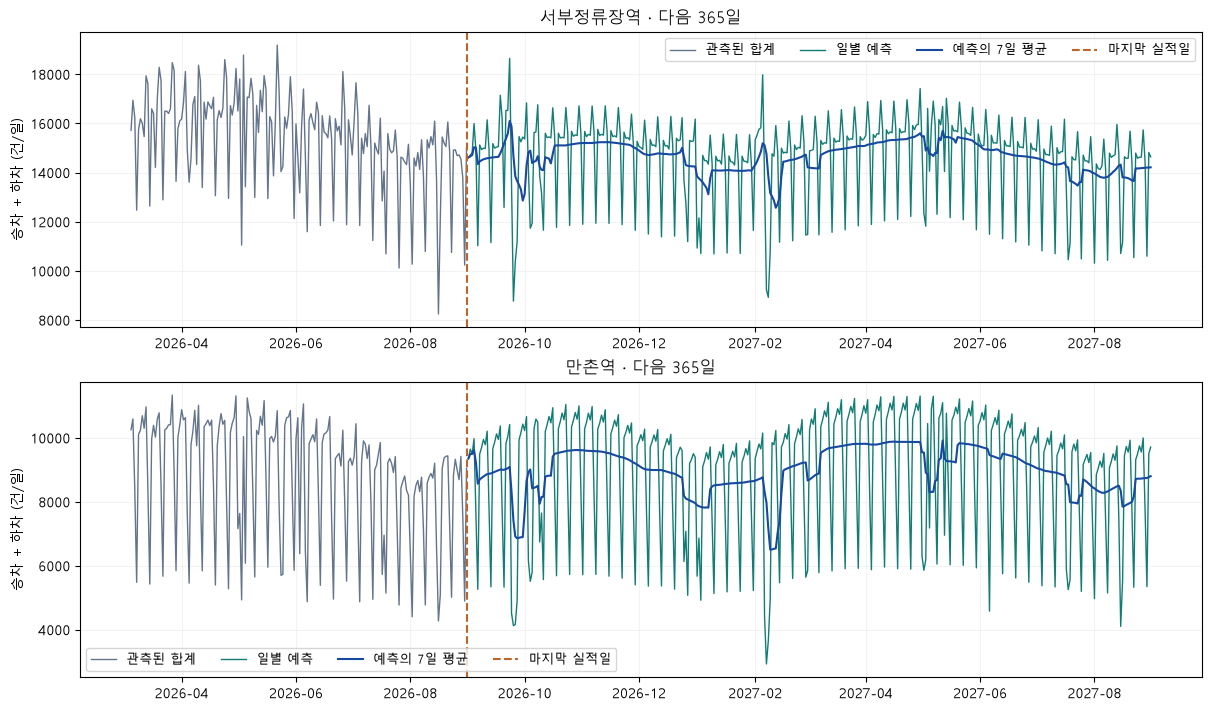

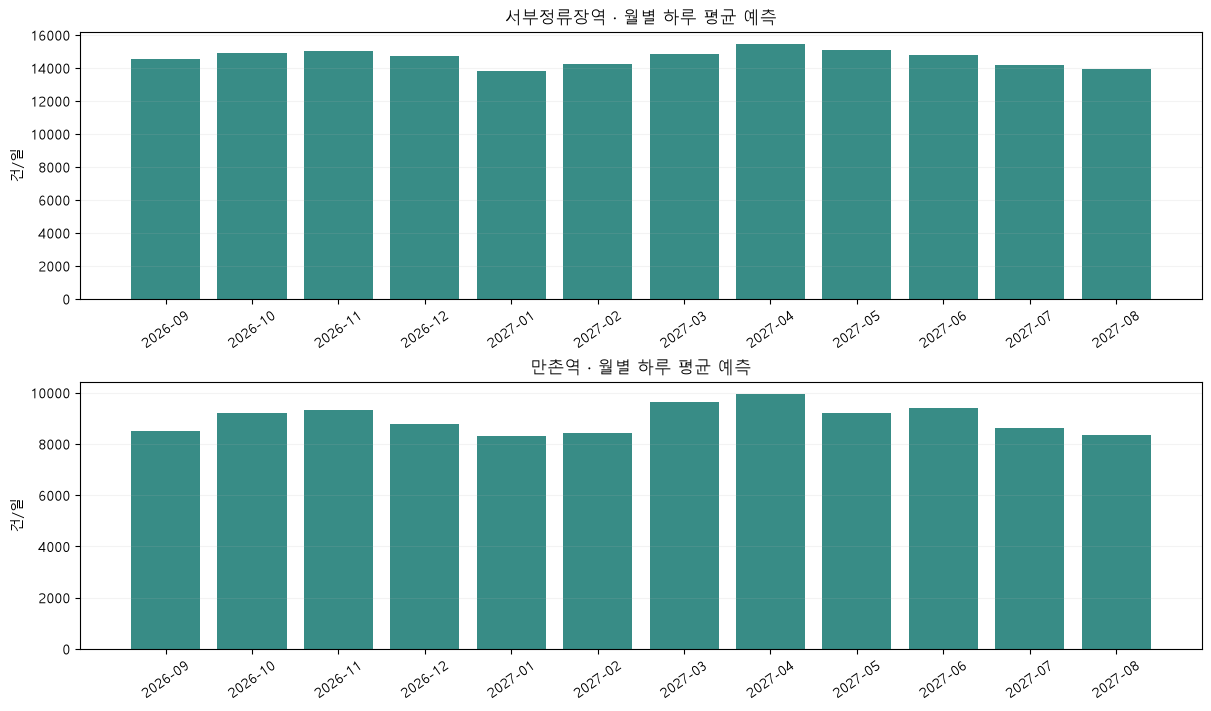

In [8]:
fig,axes=plt.subplots(2,1,figsize=(12,7),constrained_layout=True)
for ax,(station,actuals) in zip(axes,역별실적.items()):
    f=예측결과.loc[예측결과['역명'].eq(station)]
    recent=actuals.tail(180).sum(axis=1)
    ax.plot(recent.index,recent,color='#64748b',lw=1,label='관측된 합계')
    ax.plot(f['날짜'],f['예측승하차합계(건)'],color='#137d75',lw=1,label='일별 예측')
    ax.plot(f['날짜'],f['예측승하차합계(건)'].rolling(7,min_periods=1).mean(),color='#1749a0',lw=1.5,label='예측의 7일 평균')
    ax.axvline(actuals.index.max(),color='#bd642c',ls='--',label='마지막 실적일')
    ax.set(title=f'{station}역 · 다음 365일',ylabel='승차 + 하차 (건/일)')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.legend(ncol=4,fontsize=9);ax.grid(alpha=.15)
plt.show()
fig,axes=plt.subplots(2,1,figsize=(12,7),constrained_layout=True)
for ax,station in zip(axes,STATIONS):
    m=월별예측.loc[월별예측['역명'].eq(station)]
    ax.bar(m['연월'],m['하루평균승하차(건)'],color='#388c86')
    ax.set(title=f'{station}역 · 월별 하루 평균 예측',ylabel='건/일')
    ax.tick_params(axis='x',rotation=35);ax.grid(axis='y',alpha=.15)
plt.show()

## 7. 결과 저장

`테스트데이터_예측결과.csv`에는 과거 시험의 실제값과 예측값을,
`다음365일_예측결과.csv`에는 2026-09-01~2027-08-31의 일별 예측을 저장합니다.

In [9]:
시험열이름={'station':'역명','station_code':'역번호','date':'날짜','origin':'실적기준일','model':'모델','lead':'기준일이후일수',
    'actual_board':'실제승차(건)','pred_board':'예측승차(건)','actual_alight':'실제하차(건)','pred_alight':'예측하차(건)',
    'actual_total':'실제승하차합계(건)','pred_total':'예측승하차합계(건)','actual_named_holiday':'실제공휴일여부'}
시험저장=선택시험.copy()
시험저장['model']=시험저장['model'].replace(MODEL_LABELS)
시험저장=시험저장.rename(columns=시험열이름)
assert len(예측결과)==730 and not 예측결과.duplicated(['역명','날짜']).any()
assert (예측결과['예측승하차합계(건)']==예측결과['예측승차(건)']+예측결과['예측하차(건)']).all()
assert all(any('가'<=c<='힣' for c in col) for frame in [시험저장,예측결과] for col in frame.columns)
시험저장.to_csv(프로젝트폴더/'테스트데이터_예측결과.csv',index=False,encoding='utf-8-sig',date_format='%Y-%m-%d')
예측결과.to_csv(프로젝트폴더/'다음365일_예측결과.csv',index=False,encoding='utf-8-sig',date_format='%Y-%m-%d')
print('저장 완료: 테스트데이터_예측결과.csv / 다음365일_예측결과.csv')
display(pd.DataFrame([{'역명':s,'모델':MODEL_LABELS[역별모델[s]],**metric(f.actual_total,f.pred_total)}
    for s,f in 선택시험.groupby('station',sort=False)]).rename(columns=성적열이름).round(3))

저장 완료: 테스트데이터_예측결과.csv / 다음365일_예측결과.csv


,역명,모델,평가일수,평균절대오차(건),제곱평균제곱근오차(건),전체대비절대오차율(%),평균예측편차(건),합계예측오차율(%)
0,서부정류장,"CatBoost · RMSE · 최근 1,095일 · 동일가중 · 승하차별",730,663.706,918.775,4.325,-80.240,-0.523
1,만촌,"CatBoost·추세 회귀 50:50 · 최근 1,095일",730,603.689,790.901,7.349,-463.664,-5.645
